# EDA — Store Sales: Time Series Forecasting (Corporación Favorita)

Exploring the data before building models. The goal is to forecast daily sales for **54 stores × 33 product families = 1,782 series**, 16 days ahead
(scored with RMSLE). This notebook answers the questions that shaped the model design:

1. How clean is the data? Are there missing values or missing dates?
2. How are sales distributed, and how many zeros are there?
3. What trends and seasonality exist (weekly, monthly, payday)?
4. How much do product family, store, promotions, holidays and the oil price matter?
5. Which lags should be used, and what should be done about the period before a store opens?

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.titleweight": "bold", "figure.dpi": 100})
D = Path("Dataset")
train = pd.read_csv(D / "train.csv", parse_dates=["date"])
test = pd.read_csv(D / "test.csv", parse_dates=["date"])
stores = pd.read_csv(D / "stores.csv")
oil = pd.read_csv(D / "oil.csv", parse_dates=["date"])
hol = pd.read_csv(D / "holidays_events.csv", parse_dates=["date"])
trans = pd.read_csv(D / "transactions.csv", parse_dates=["date"])

## 1. Data overview

In [2]:
info = pd.DataFrame({
    "rows": [len(train), len(test), len(stores), len(oil), len(hol), len(trans)],
    "date_min": [train.date.min(), test.date.min(), None, oil.date.min(), hol.date.min(), trans.date.min()],
    "date_max": [train.date.max(), test.date.max(), None, oil.date.max(), hol.date.max(), trans.date.max()],
}, index=["train", "test", "stores", "oil", "holidays_events", "transactions"])
display(info)
print(f"stores={train.store_nbr.nunique()}  families={train.family.nunique()}  series={train.groupby(['store_nbr','family']).ngroups}")
print(f"train: {train.date.nunique()} days | test: {test.date.nunique()} days "
      f"({test.date.min().date()} -> {test.date.max().date()}, starts {(test.date.min()-train.date.max()).days} day after train)")
train.head()

,rows,date_min,date_max
train,3000888,2013-01-01,2017-08-15
test,28512,2017-08-16,2017-08-31
stores,54,NaT,NaT
oil,1218,2013-01-01,2017-08-31
holidays_events,350,2012-03-02,2017-12-26
transactions,83488,2013-01-01,2017-08-15


stores=54  families=33  series=1782
train: 1684 days | test: 16 days (2017-08-16 -> 2017-08-31, starts 1 day after train)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


## 2. Data quality: missing values, duplicates and missing dates

In [3]:
print("Missing values per table")
display(pd.DataFrame({n: t.isna().sum() for n, t in dict(train=train, test=test, stores=stores, oil=oil, hol=hol, trans=trans).items()}).T.loc[:, lambda d: d.sum() > 0])
print("duplicate (date, store, family) rows in train:", train.duplicated(["date", "store_nbr", "family"]).sum())

all_days = pd.date_range(train.date.min(), train.date.max())
missing_days = all_days.difference(train.date.unique())
print("calendar days missing from train:", [d.strftime("%Y-%m-%d") for d in missing_days])
print("oil prices missing:", oil.dcoilwtico.isna().sum(), "of", len(oil), "(interpolated in the model)")

Missing values per table


,dcoilwtico
train,NaN
test,NaN
stores,NaN
oil,43.0
hol,NaN
trans,NaN


duplicate (date, store, family) rows in train: 0
calendar days missing from train: ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']
oil prices missing: 43 of 1218 (interpolated in the model)


**Observations:** the main tables have no missing values. Only `oil` is missing some days (market holidays), and **25 December** is absent every year
(stores are closed). If lags are computed by counting "rows" instead of "days", every lag after that date drifts by one day, so the date grid should be completed first.

## 3. Distribution of sales (the target)

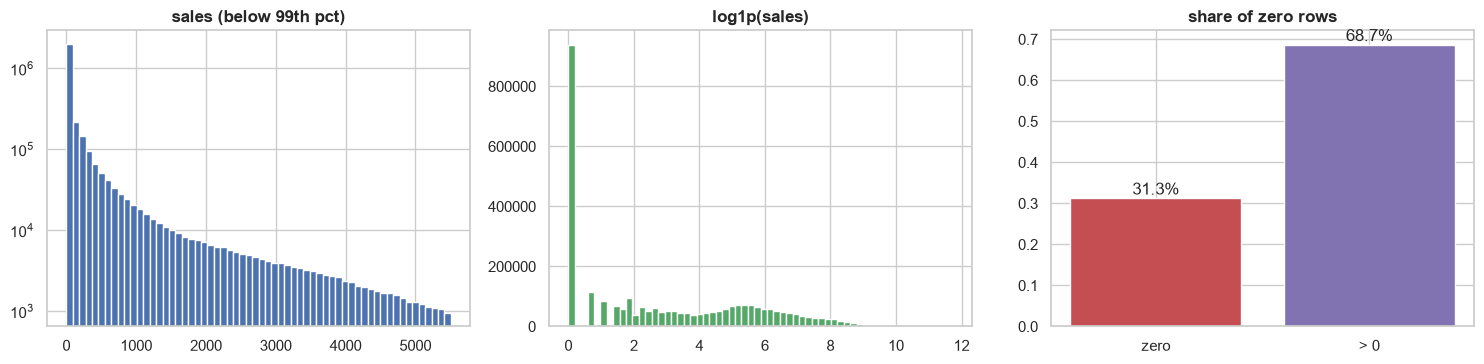

count    3000888.00
mean         357.78
std         1102.00
min            0.00
25%            0.00
50%           11.00
75%          195.85
max       124717.00
skew raw = 7.4  |  skew log1p = 0.41


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
s = train.sales
ax[0].hist(s[s < s.quantile(.99)], bins=60, color="#4c72b0"); ax[0].set_title("sales (below 99th pct)"); ax[0].set_yscale("log")
ax[1].hist(np.log1p(s), bins=60, color="#55a868"); ax[1].set_title("log1p(sales)")
zero = (s == 0).mean()
ax[2].bar(["zero", "> 0"], [zero, 1 - zero], color=["#c44e52", "#8172b2"]); ax[2].set_title("share of zero rows")
for i, v in enumerate([zero, 1 - zero]): ax[2].text(i, v, f"{v:.1%}", ha="center", va="bottom")
plt.tight_layout(); plt.show()
print(s.describe().round(2).to_string())
print(f"skew raw = {s.skew():.1f}  |  skew log1p = {np.log1p(s).skew():.2f}")

**Observations:** sales are heavily right-skewed and contain many zeros. Transforming with `log1p` gives a far more reasonable distribution and matches the RMSLE metric,
so the models are trained on `log1p(sales)` and converted back with `expm1`.

## 4. Trend and seasonality

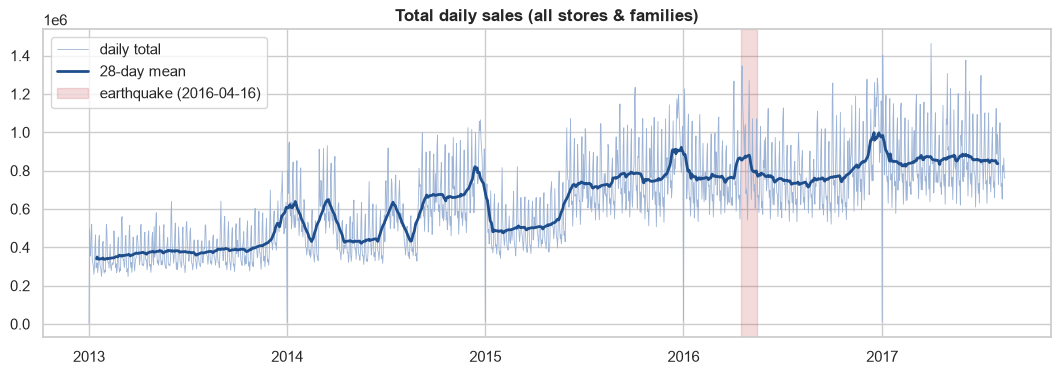

In [5]:
daily = train.groupby("date").sales.sum()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily.index, daily.values, lw=.6, color="#9db4d6", label="daily total")
ax.plot(daily.index, daily.rolling(28, center=True).mean(), lw=2, color="#1f4e8c", label="28-day mean")
ax.axvspan(pd.Timestamp("2016-04-16"), pd.Timestamp("2016-05-16"), color="#c44e52", alpha=.2, label="earthquake (2016-04-16)")
ax.set_title("Total daily sales (all stores & families)"); ax.legend(); plt.show()

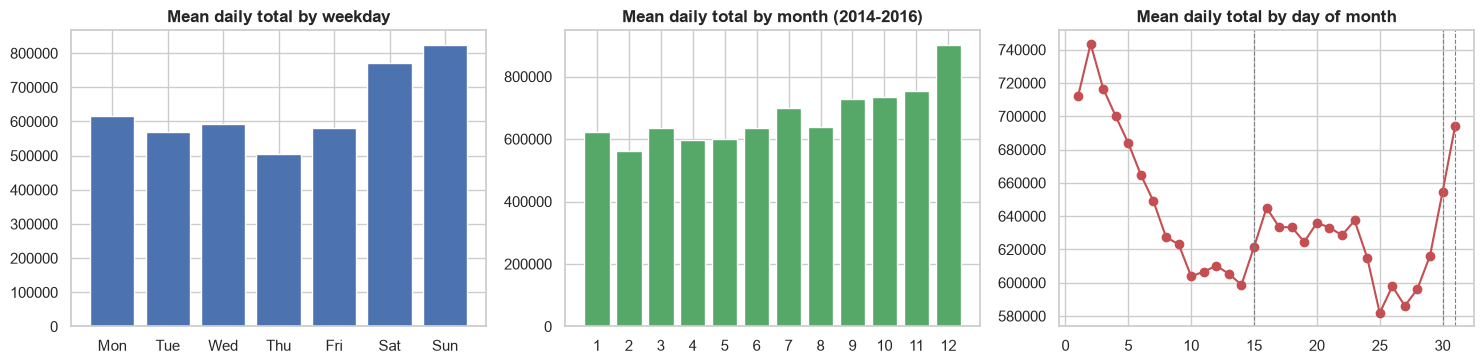

In [6]:
d = train.assign(dow=train.date.dt.dayofweek, month=train.date.dt.month, dom=train.date.dt.day, year=train.date.dt.year)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
dd = d.groupby(["date", "dow"]).sales.sum().reset_index().groupby("dow").sales.mean()
ax[0].bar(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], dd.values, color="#4c72b0"); ax[0].set_title("Mean daily total by weekday")
mm = d[d.year.between(2014, 2016)].groupby(["date", "month"]).sales.sum().reset_index().groupby("month").sales.mean()
ax[1].bar(mm.index, mm.values, color="#55a868"); ax[1].set_title("Mean daily total by month (2014-2016)"); ax[1].set_xticks(range(1, 13))
dm = d.groupby(["date", "dom"]).sales.sum().reset_index().groupby("dom").sales.mean()
ax[2].plot(dm.index, dm.values, marker="o", color="#c44e52"); ax[2].set_title("Mean daily total by day of month")
for x in (15, 30, 31): ax[2].axvline(x, ls="--", color="gray", lw=.8)
plt.tight_layout(); plt.show()

**Observations (numbers from the data):**
- **Steady growth:** the average total per day rises from about 386k (2013) to 575k, 662k, 791k and 856k (2017)
- **Clear weekly pattern:** Saturday (≈772k) and Sunday (≈825k) are highest, Thursday is lowest (≈505k)
- **Yearly pattern:** December is highest (≈902k) and February lowest (≈562k)
- **Within the month:** sales are higher at the **start and end of the month** (days 1–3 ≈ 712–743k, days 30–31 ≈ 655–694k) and lower mid-month.
  The 15th has only a small effect (≈599k → 645k on the 16th), so the "payday" effect is clearer at month end than on the 15th
- For the period after the April 2016 earthquake, see section 12

## 5. Product families

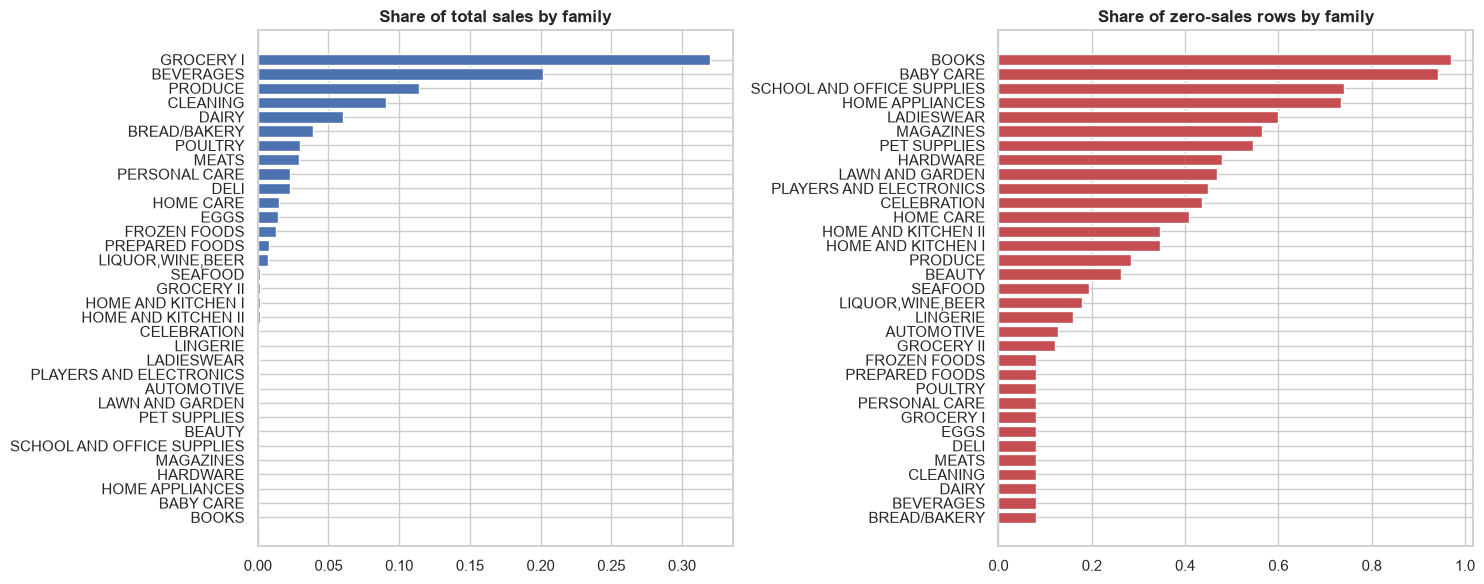

top-3 families = 64% of all sales


In [7]:
fam = train.groupby("family").agg(total=("sales", "sum"), zero_share=("sales", lambda x: (x == 0).mean()))
fam["share"] = fam.total / fam.total.sum()
fam = fam.sort_values("total", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].barh(fam.index[::-1], fam.share[::-1], color="#4c72b0"); ax[0].set_title("Share of total sales by family")
f2 = fam.sort_values("zero_share")
ax[1].barh(f2.index, f2.zero_share, color="#c44e52"); ax[1].set_title("Share of zero-sales rows by family")
plt.tight_layout(); plt.show()
print("top-3 families = %.0f%% of all sales" % (fam.share.head(3).sum() * 100))

**Observations:** the top 3 families make up **64%** of all sales (left chart), while some families barely sell:
BOOKS is zero in 97% of rows, BABY CARE 94%, and SCHOOL AND OFFICE SUPPLIES and HOME APPLIANCES about 74% (steady sellers such as CLEANING,
MEATS and BREAD/BAKERY are zero in only 8%). This difference in scale is why the `family` feature is needed, and why the log transform helps by reducing the weight of the high-volume families.

## 6. Stores

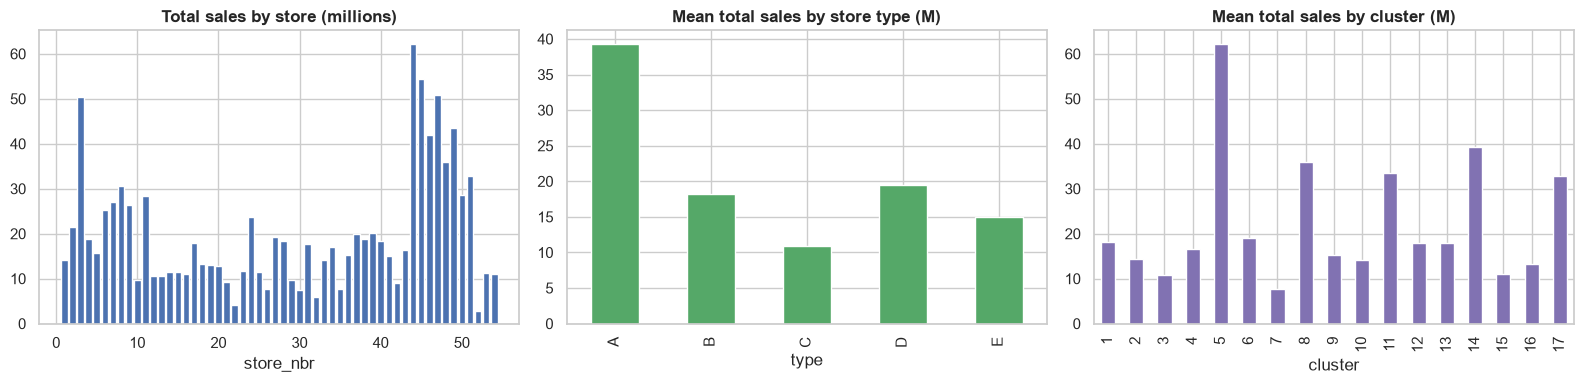

{'A': 9, 'B': 8, 'C': 15, 'D': 18, 'E': 4} | cities: 22 | states: 16


In [8]:
st = train.groupby("store_nbr").sales.sum().rename("total").reset_index().merge(stores, on="store_nbr")
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].bar(st.store_nbr, st.total / 1e6, color="#4c72b0"); ax[0].set_title("Total sales by store (millions)"); ax[0].set_xlabel("store_nbr")
st.groupby("type").total.mean().div(1e6).plot.bar(ax=ax[1], color="#55a868"); ax[1].set_title("Mean total sales by store type (M)")
st.groupby("cluster").total.mean().div(1e6).plot.bar(ax=ax[2], color="#8172b2"); ax[2].set_title("Mean total sales by cluster (M)")
plt.tight_layout(); plt.show()
print(stores.groupby("type").size().to_dict(), "| cities:", stores.city.nunique(), "| states:", stores.state.nunique())

## 7. Promotions (onpromotion)

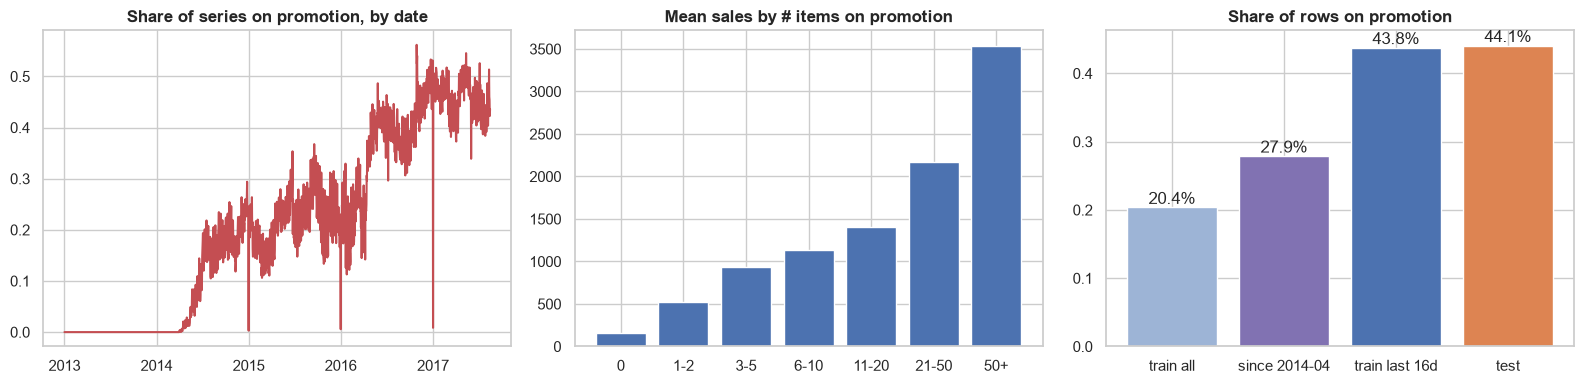

corr(onpromotion, log1p(sales)) = 0.329
promotion data exists only from 2014-04-01


In [9]:
pr = train.groupby("date").agg(promo_share=("onpromotion", lambda x: (x > 0).mean()), sales=("sales", "sum"))
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(pr.index, pr.promo_share, color="#c44e52"); ax[0].set_title("Share of series on promotion, by date")
b = pd.cut(train.onpromotion, [-1, 0, 2, 5, 10, 20, 50, 1e4], labels=["0", "1-2", "3-5", "6-10", "11-20", "21-50", "50+"])
m = train.groupby(b).sales.mean()
ax[1].bar(m.index.astype(str), m.values, color="#4c72b0"); ax[1].set_title("Mean sales by # items on promotion")
last16 = train[train.date > train.date.max() - pd.Timedelta(days=16)]
v = [(train.onpromotion > 0).mean(), (train[train.date >= "2014-04-01"].onpromotion > 0).mean(), (last16.onpromotion > 0).mean(), (test.onpromotion > 0).mean()]
ax[2].bar(["train all", "since 2014-04", "train last 16d", "test"], v, color=["#9db4d6", "#8172b2", "#4c72b0", "#dd8452"])
for i, x in enumerate(v): ax[2].text(i, x, f"{x:.1%}", ha="center", va="bottom")
ax[2].set_title("Share of rows on promotion")
plt.tight_layout(); plt.show()
print(f"corr(onpromotion, log1p(sales)) = {np.corrcoef(train.onpromotion, np.log1p(train.sales))[0,1]:.3f}")
print("promotion data exists only from", train.loc[train.onpromotion > 0, "date"].min().date())

**Observations:**
- Promotion data exists only from **2014-04-01** (before that it is all zeros, which means "not recorded", not "no promotions")
- Average sales rise clearly with the number of items on promotion: 0 items ≈ 158 units → 3–5 items ≈ 935 → 50+ items ≈ 3,540
  (partly because large families are promoted more often, so this is not a purely causal effect; the correlation with log sales is 0.33)
- The share of rows on promotion grows over time: the test period is ≈ 44%, **the same as the last 16 days of training (≈ 44%)**, but higher than the average over the whole training period (≈ 20%).
  So it is not a sudden change, just the latest level the model has already seen
- `onpromotion` is known in advance for the test period, so it can be used directly

## 8. Holidays and events

locale      Local  National  Regional
type                                 
Additional     11        40         0
Bridge          0         5         0
Event           0        56         0
Holiday       137        60        24
Transfer        4         8         0
Work Day        0         5         0
transferred holidays: 12


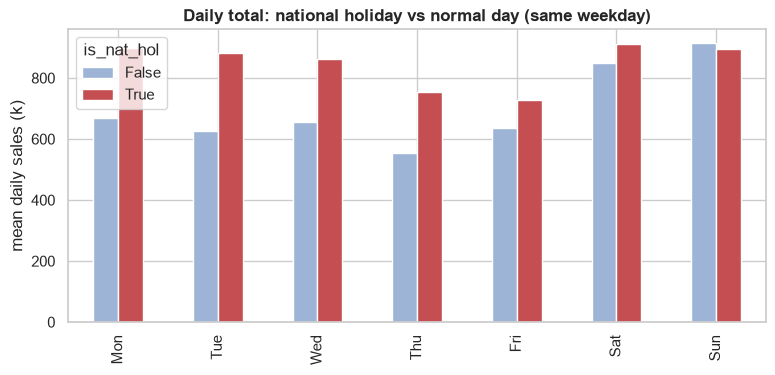

In [10]:
print(hol.groupby(["type", "locale"]).size().unstack(fill_value=0))
print("transferred holidays:", hol.transferred.sum())
nat = hol[(hol.locale == "National") & (~hol.transferred) & hol.type.isin(["Holiday", "Transfer", "Additional", "Bridge"])].date.unique()
dly = train.groupby("date").sales.sum().to_frame("sales")
dly["is_nat_hol"] = dly.index.isin(nat)
dly["dow"] = dly.index.dayofweek
res = dly[dly.index.year >= 2014].groupby(["dow", "is_nat_hol"]).sales.mean().unstack()
res.index = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]
ax = res.div(1e3).plot.bar(figsize=(9, 3.8), color=["#9db4d6", "#c44e52"]); ax.set_ylabel("mean daily sales (k)")
ax.set_title("Daily total: national holiday vs normal day (same weekday)"); plt.show()

**Observations:**
- National holidays that fall on **Monday to Thursday** have totals ≈ **32–40% higher** than a normal day of the same weekday (Friday ≈ +14%, Saturday ≈ +7%).
  Those on **Sunday are almost no different** (≈ −2%), because Sunday is already a high-sales day.
  (Caveat: many holidays fall in December, which is high season anyway, so this figure includes a seasonal effect)
- Watch for holidays that were **transferred (transferred = True, 12 days)**: the originally announced date counts as a normal day, and the day it was actually celebrated is in the `Transfer` rows
- In the experiments, adding richer holiday features (bridge days, work days, distance to a holiday) **did not reduce RMSLE** (0.38571 → 0.38595),
  because the basic holiday and calendar features already capture the main effect

## 9. Oil price and transactions

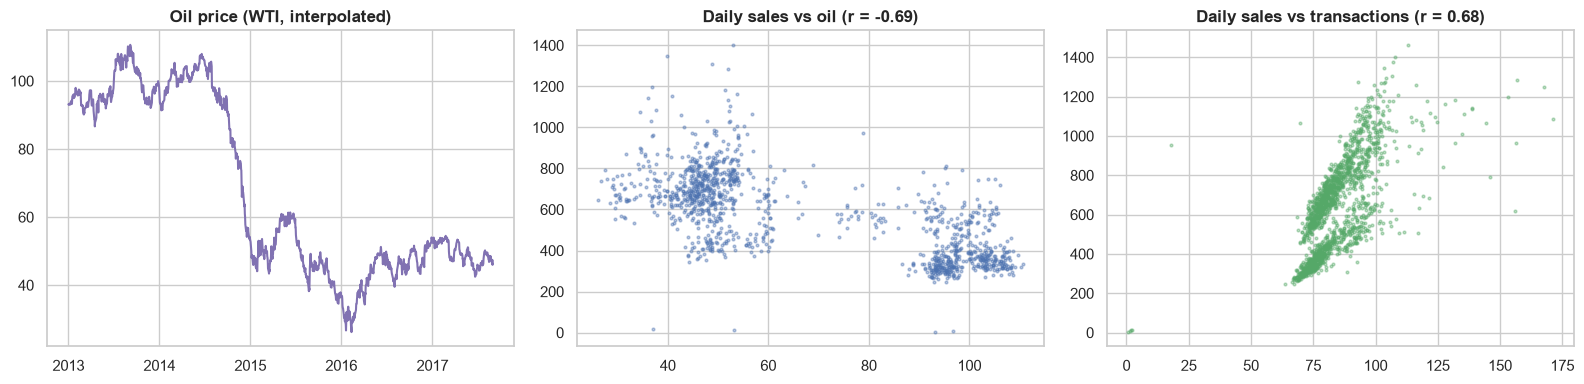

transactions end: 2017-08-15 | train end: 2017-08-15 | test starts: 2017-08-16


In [11]:
o = oil.set_index("date").dcoilwtico.interpolate().bfill()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(o.index, o.values, color="#8172b2"); ax[0].set_title("Oil price (WTI, interpolated)")
j = pd.concat([daily.rename("sales"), o.rename("oil")], axis=1).dropna()
ax[1].scatter(j.oil, j.sales / 1e3, s=4, alpha=.4, color="#4c72b0"); ax[1].set_title(f"Daily sales vs oil (r = {j.corr().iloc[0,1]:.2f})")
tt = trans.groupby("date").transactions.sum()
j2 = pd.concat([daily.rename("sales"), tt], axis=1).dropna()
ax[2].scatter(j2.transactions / 1e3, j2.sales / 1e3, s=4, alpha=.4, color="#55a868"); ax[2].set_title(f"Daily sales vs transactions (r = {j2.corr().iloc[0,1]:.2f})")
plt.tight_layout(); plt.show()
print("transactions end:", trans.date.max().date(), "| train end:", train.date.max().date(), "| test starts:", test.date.min().date())

**Observations:**
- The oil price is **inversely** related to total sales (r ≈ −0.69): the price fell during 2014–2016 while sales kept growing with the trend,
  so the two are linked mainly through time, not directly
- `transactions` correlates with total sales at r ≈ **+0.68**, but **the data ends on 2017-08-15, the last training day, so it does not exist for the test period**.
  It cannot be used as a feature for forecasting ahead (it would have to be forecast itself first, with a risk of leaking the future)

## 10. Series that have not started selling (zeros before opening)

series that never sell: 53 of 1782
zero rows that are *leading* zeros (before the first sale): 466,956 = 49.7% of all zero rows


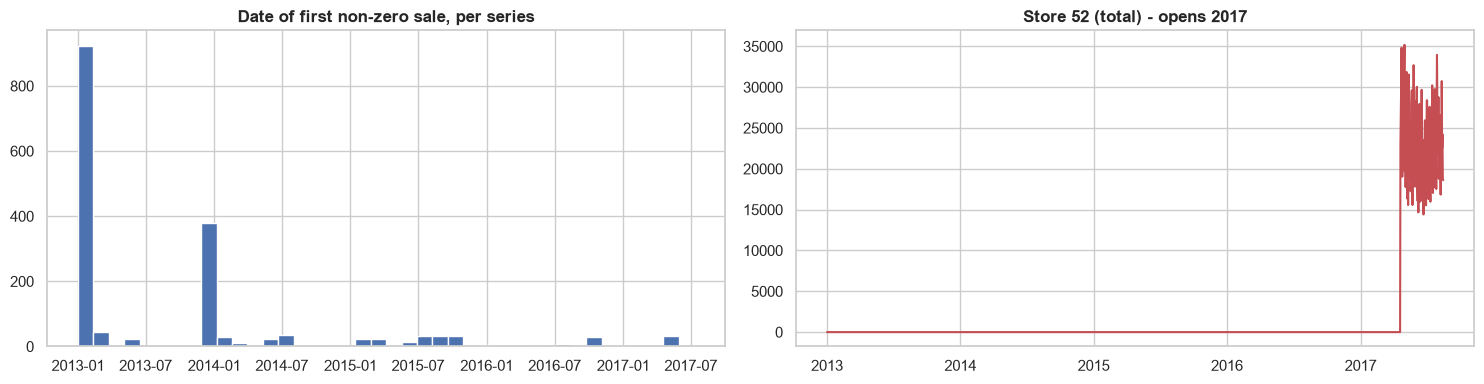

In [12]:
piv = train.pivot_table(index=["store_nbr", "family"], columns="date", values="sales", aggfunc="sum")
first = piv.gt(0).idxmax(axis=1).where(piv.gt(0).any(axis=1))
never = piv.gt(0).any(axis=1).eq(False).sum()
lead_zero = (piv.columns.values[None, :] < first.values[:, None]) & piv.eq(0).values
print(f"series that never sell: {never} of {len(piv)}")
print(f"zero rows that are *leading* zeros (before the first sale): {lead_zero.sum():,} = {lead_zero.sum() / (train.sales == 0).sum():.1%} of all zero rows")
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
fs = first.dropna(); ax[0].hist(fs, bins=40, color="#4c72b0"); ax[0].set_title("Date of first non-zero sale, per series")
ex = piv.loc[52].sum().rename("sales"); ax[1].plot(ex.index, ex.values, color="#c44e52"); ax[1].set_title("Store 52 (total) - opens 2017")
plt.tight_layout(); plt.show()

**Key observation:** zero rows are **31%** of the data, and **about half (49.7%) of all zeros are zeros from before the series really started selling**,
not genuine zero demand (for example store 52 started selling on 2017-04-20), and 53 series never sold at all.
These zeros distort the lags and rolling means of series that opened later. Dropping this period (both as training rows and as lag values)
was the most effective improvement to the model (RMSLE 0.39001 → 0.38571).

## 11. Relationship with the past (what decides which lags to use)

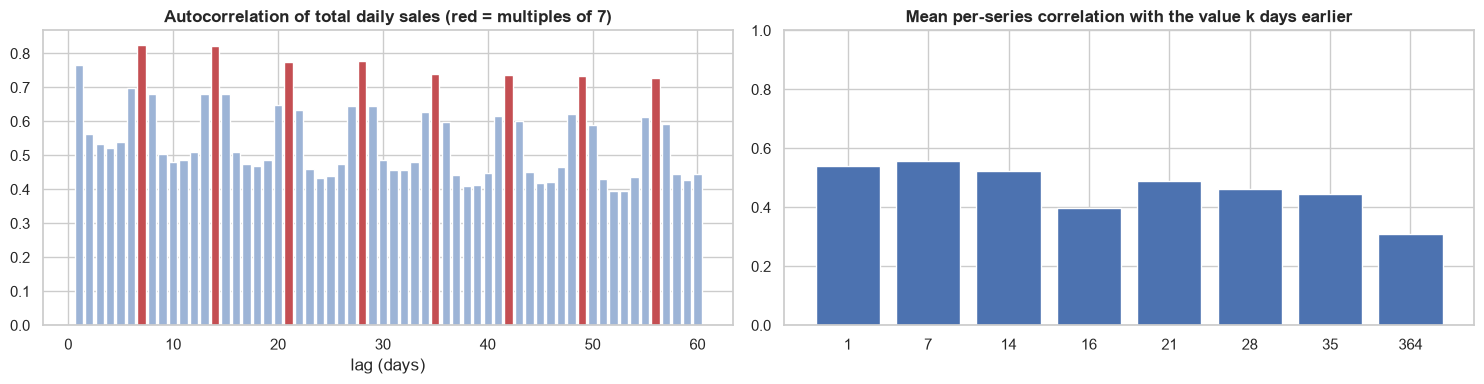

In [13]:
tot = daily.copy()
acf = pd.Series([tot.autocorr(k) for k in range(1, 61)], index=range(1, 61))
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].bar(acf.index, acf.values, color=["#c44e52" if k % 7 == 0 else "#9db4d6" for k in acf.index])
ax[0].set_title("Autocorrelation of total daily sales (red = multiples of 7)"); ax[0].set_xlabel("lag (days)")
L = np.log1p(piv.fillna(0).values)
lags = [1, 7, 14, 16, 21, 28, 35, 364]
cor = [np.nanmean([np.corrcoef(L[i, k:], L[i, :-k])[0, 1] for i in range(0, len(L), 7) if L[i].std() > 0]) for k in lags]
ax[1].bar([str(k) for k in lags], cor, color="#4c72b0"); ax[1].set_title("Mean per-series correlation with the value k days earlier"); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

**Observations:**
- Daily totals: correlation is high at lag 7 (0.83), 14 (0.82), 21 (0.77) and 28 (0.78) but **drops at lag 16 (0.51)**, which is not a multiple of 7.
  So "the same weekday" matters more than "the most recent"
- Per series (much noisier) the correlations are lower: lag 7 ≈ 0.56, lag 16 ≈ 0.40, lag 21 ≈ 0.49, lag 28 ≈ 0.46 and **lag 364 is the lowest at ≈ 0.31**,
  so lag 364 should not be expected to be strong (it only helps with yearly seasonality)
- Because we must forecast 16 days ahead, we use lags of **at least 16 days** (16, 17, 21, 28, 35, 364) and rolling means shifted by 16 days,
  so no information is used that would not exist on the real forecast day

## 12. The April 2016 earthquake

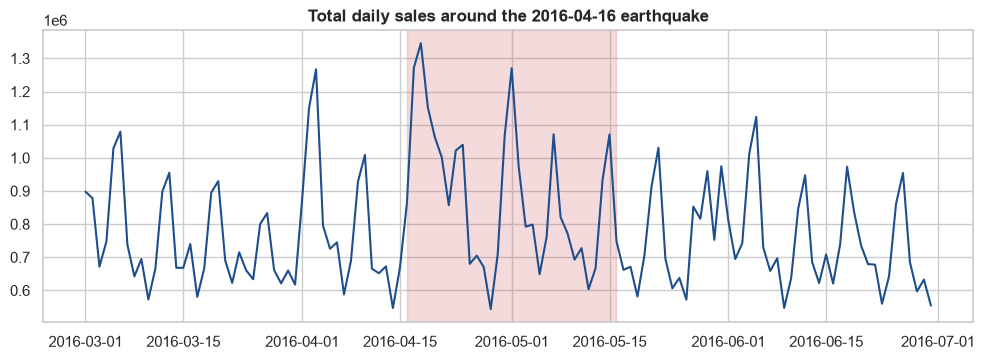

2016: mean daily sales before 763,180  ->  after 881,919  (+15.6%)
2015 (same calendar windows, no earthquake): +2.2%


In [14]:
w = daily["2016-03-01":"2016-06-30"]
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(w.index, w.values, color="#1f4e8c"); ax.axvspan("2016-04-16", "2016-05-16", color="#c44e52", alpha=.2)
ax.set_title("Total daily sales around the 2016-04-16 earthquake")
plt.show()
b = daily["2016-03-01":"2016-04-15"].mean(); a = daily["2016-04-16":"2016-05-16"].mean()
print(f"2016: mean daily sales before {b:,.0f}  ->  after {a:,.0f}  ({a / b - 1:+.1%})")
b0 = daily["2015-03-01":"2015-04-15"].mean(); a0 = daily["2015-04-16":"2015-05-16"].mean()
print(f"2015 (same calendar windows, no earthquake): {a0 / b0 - 1:+.1%}")

**Observations:** in the same calendar window of 2015 (no earthquake) sales rose only ≈ +2%, but in 2016 they rose ≈ +16%, an excess of about 13 percentage points
that probably comes from people buying relief supplies after the earthquake (though it cannot be separated from the upward trend with certainty), so an `earthquake` feature is used to help the model.

## 13. Test period compared with the training period

In [15]:
print("test covers:", test.date.min().date(), "->", test.date.max().date(), "| rows per day:", test.groupby("date").size().iloc[0])
print("same stores/families as train:", set(test.store_nbr) == set(train.store_nbr), set(test.family) == set(train.family))
same = train[(train.date.dt.month == 8) & (train.date.dt.day.between(16, 31)) & (train.date.dt.year == 2016)]
print(f"mean sales in the same calendar window of 2016: {same.sales.mean():.1f} | last 16 days of train: {train[train.date > train.date.max() - pd.Timedelta(days=16)].sales.mean():.1f}")

test covers: 2017-08-16 -> 2017-08-31 | rows per day: 1782


same stores/families as train: True True


mean sales in the same calendar window of 2016: 398.5 | last 16 days of train: 467.1


**Observations:** the test period has the same stores and product families as the training period (no new stores) and 1,782 rows per day. The average of the last 16 days of training (≈ 467)
is about 17% higher than the same dates the previous year (≈ 398), in line with the upward trend, so last year's values alone should not be used as the baseline.

## 14. Summary of findings and their effect on the model

| Finding | Effect on the design |
|---|---|
| Sales are right-skewed with many zeros | Train on `log1p(sales)` to match RMSLE |
| Clear weekly cycle; lag 16 is weaker than lag 21/28 | Use lags 21, 28, 35 (same weekday) |
| Forecast is 16 days ahead | Every lag and rolling mean is shifted by at least 16 days |
| 25 December is missing every year | Complete the date grid before computing lags |
| Many zeros are from before the store opened | Drop that period (the most effective improvement) |
| Promotions are strongly related to sales (0 → 50+ items: ≈158 → 3,540 units) and known in advance | Use `onpromotion` and its 7-day mean |
| Sales are higher at month start and end (the 15th only slightly), and the earthquake mattered | Features `payday`, `dom`, `earthquake` |
| `transactions` does not exist for the test period | Not used |
| Sales are concentrated in a few product families | Features `family`, `store_nbr`, and embeddings in the LSTM |